In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score

In [3]:
df = pd.read_excel('Berlin_wind_multiclass1.xlsx')

In [4]:
df.head()

,Year,Month,Day,Hour,Minute,Temperature,Clearsky.DHI,Clearsky.DNI,Clearsky.GHI,Cloud.Type,...,GHI,Ozone,Relative.Humidity,Solar.Zenith.Angle,Surface.Albedo,Pressure,Precipitable.Water,Wind.Direction,Wind.Speed,X50Hertz..MW.
0,2018,1,1,0,0,7.9,0,0,0,7,...,0,0.287,93.39,148.97,0.12,993,1.9,212,5.6,713.29
1,2018,1,1,0,15,7.9,0,0,0,8,...,0,0.287,93.39,147.97,0.12,993,1.9,213,5.7,701.46
2,2018,1,1,0,30,7.8,0,0,0,8,...,0,0.286,94.03,146.76,0.12,993,2.0,214,5.8,701.96
3,2018,1,1,0,45,7.7,0,0,0,7,...,0,0.286,91.31,145.35,0.12,993,2.0,214,5.8,733.83
4,2018,1,1,1,0,7.7,0,0,0,7,...,0,0.286,91.31,143.78,0.12,993,2.0,215,5.9,753.35


In [5]:
print(df.shape)

(70080, 24)


Boundaries: [ 34.1    71.418 126.18  234.32 ]

Class counts:
target
0    14026
1    14006
2    14021
3    14012
4    14015
Name: count, dtype: int64


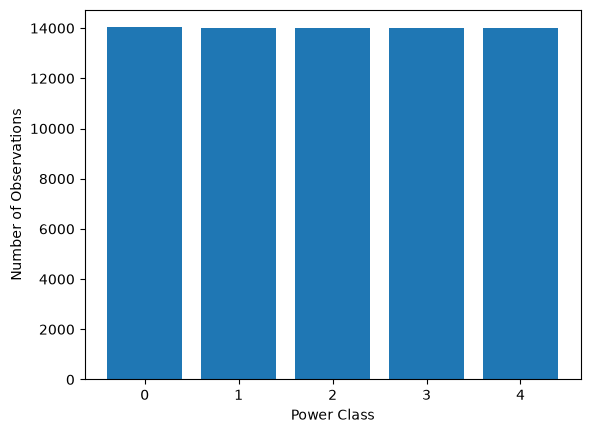

In [6]:
power = df['X50Hertz..MW.']

boundaries = power.quantile([0.2, 0.4, 0.6, 0.8]).values

conditions = [
    power <= boundaries[0],
    (power > boundaries[0]) & (power <= boundaries[1]),
    (power > boundaries[1]) & (power <= boundaries[2]),
    (power > boundaries[2]) & (power <= boundaries[3]),
    power > boundaries[3]
]

choices = [0, 1, 2, 3, 4]

df['target'] = np.select(conditions, choices)

print("Boundaries:", boundaries)
print("\nClass counts:")
print(df['target'].value_counts().sort_index())

plt.hist(df['target'], bins=np.arange(-0.5, 5.5, 1), rwidth=0.8)
plt.xticks(range(5))
plt.xlabel('Power Class')
plt.ylabel('Number of Observations')
plt.show()



In [7]:
print(df.head())

print(df.shape)
print(df.columns)
df.info()

   Year  Month  Day  Hour  Minute  Temperature  Clearsky.DHI  Clearsky.DNI  \
0  2018      1    1     0       0          7.9             0             0   
1  2018      1    1     0      15          7.9             0             0   
2  2018      1    1     0      30          7.8             0             0   
3  2018      1    1     0      45          7.7             0             0   
4  2018      1    1     1       0          7.7             0             0   

   Clearsky.GHI  Cloud.Type  ...  Ozone  Relative.Humidity  \
0             0           7  ...  0.287              93.39   
1             0           8  ...  0.287              93.39   
2             0           8  ...  0.286              94.03   
3             0           7  ...  0.286              91.31   
4             0           7  ...  0.286              91.31   

   Solar.Zenith.Angle  Surface.Albedo  Pressure  Precipitable.Water  \
0              148.97            0.12       993                 1.9   
1              1

In [8]:
print(df.isna().sum())

Year                  0
Month                 0
Day                   0
Hour                  0
Minute                0
Temperature           0
Clearsky.DHI          0
Clearsky.DNI          0
Clearsky.GHI          0
Cloud.Type            0
Dew.Point             0
DHI                   0
DNI                   0
Fill.Flag             0
GHI                   0
Ozone                 0
Relative.Humidity     0
Solar.Zenith.Angle    0
Surface.Albedo        0
Pressure              0
Precipitable.Water    0
Wind.Direction        0
Wind.Speed            0
X50Hertz..MW.         0
target                0
dtype: int64


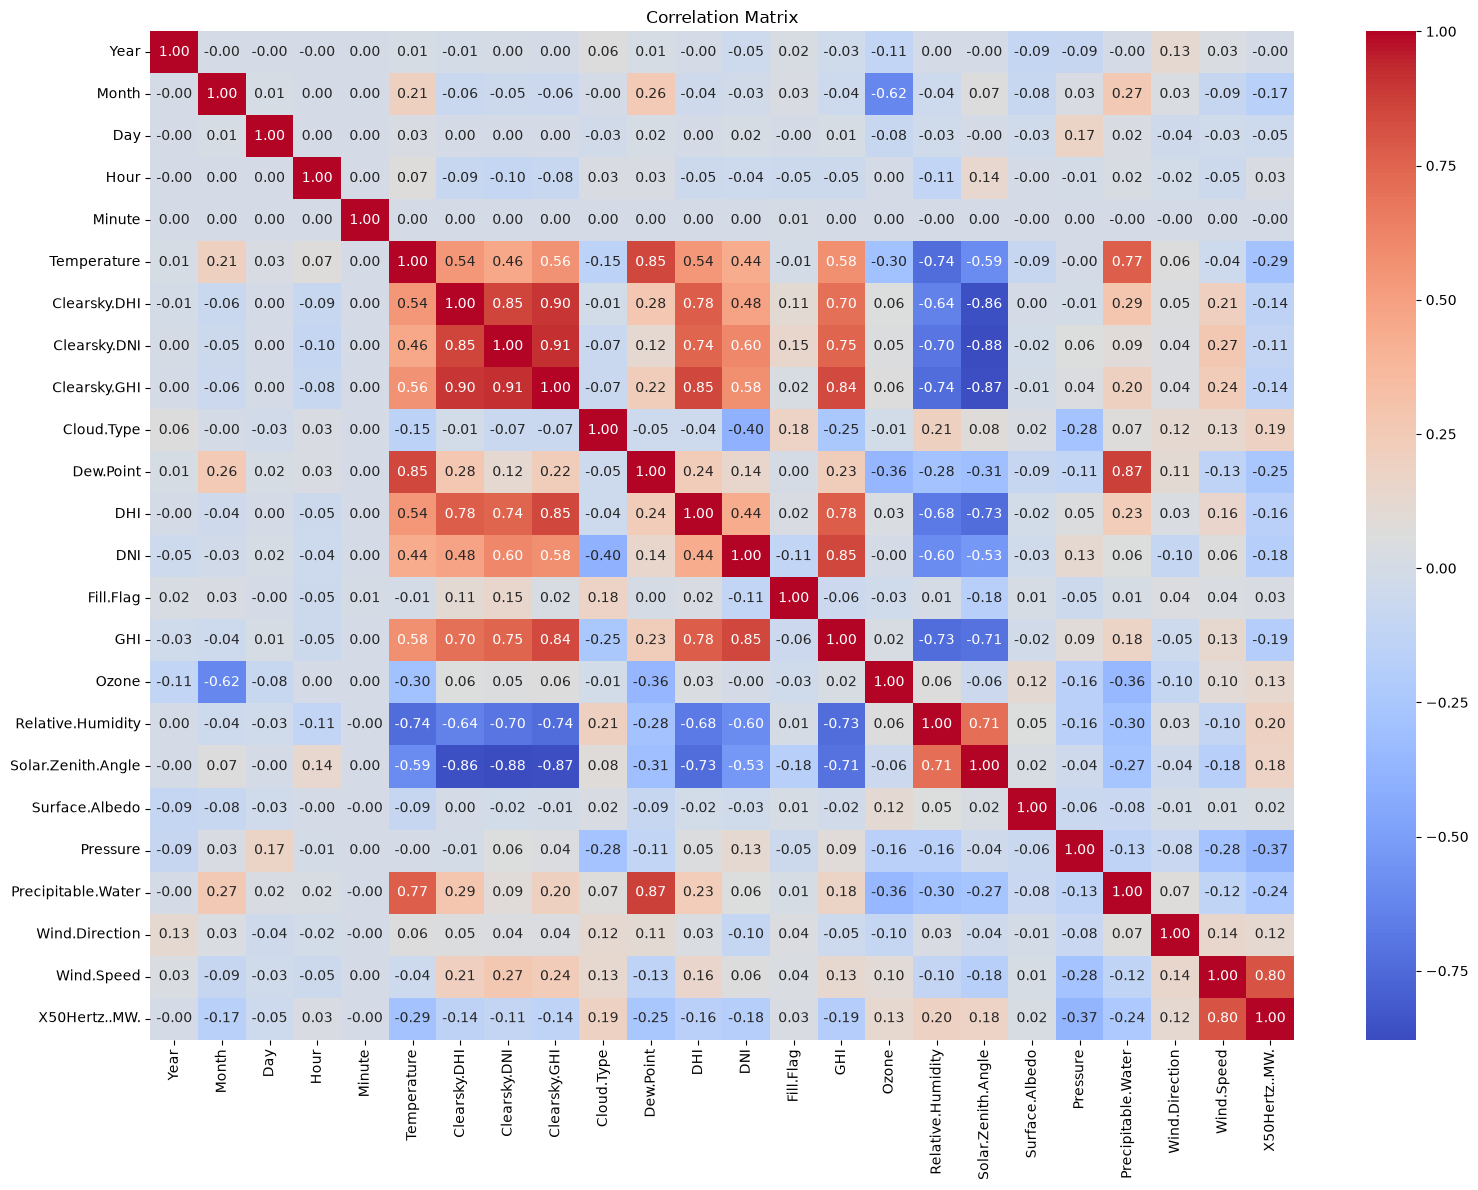

In [9]:
corr = df.drop(columns=['target']).corr(numeric_only=True)

plt.figure(figsize=(16, 12))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [17]:
def train_federated_multiclass_xgboost(df, feature_cols, target_col='target', n_trees=100, learning_rate=0.1, reg_lambda=1.0):
    df = df.copy()

    # Randomly shuffle and split dataset into 3 parts ONCE
    df_shuffled = df.sample(frac=1, random_state=42).reset_index(drop=True)
    chunk_size = len(df_shuffled) // 3
    
    clients = [
        df_shuffled.iloc[0 : chunk_size].copy(),
        df_shuffled.iloc[chunk_size : 2 * chunk_size].copy(),
        df_shuffled.iloc[2 * chunk_size :].copy()
    ]

    classes = sorted(df[target_col].unique())

    # Initialize raw scores (logits Z) for each class to 0.0 for all clients
    for client in clients:
        for k in classes:
            client[f"Z_{k}"] = 0.0

    # Compute global quantile bin blueprints for EVERY feature column ONCE
    global_bin_blueprints = {}
    for col in feature_cols:
        local_quantiles = [
            np.percentile(client[col], np.linspace(0, 100, 11))  # 10 bins / deciles
            for client in clients
        ]
        global_bin_blueprints[col] = np.unique(np.concatenate(local_quantiles))

    all_trained_trees = []

    print(f"\nStarting federated multi-class training for {n_trees} rounds...")

    # Boosting loop (each round trains one tree per class using softmax gradients/hessians)
    for tree_no in range(n_trees):
        round_trees = []

        # 1. Update softmax probabilities for all clients before the round
        for client in clients:
            logits = np.column_stack([client[f"Z_{k}"].values for k in classes])
            exp_logits = np.exp(logits - np.max(logits, axis=1, keepdims=True))
            probs = exp_logits / np.sum(exp_logits, axis=1, keepdims=True)
            
            for idx, k in enumerate(classes):
                client[f"p_{k}"] = probs[:, idx]

        # 2. Train a tree for each class independently
        for k in classes:
            best_overall_gain = -np.inf
            best_feature = None
            best_split = None
            best_weights = None

            # Server evaluates gain across all features for class k
            for col in feature_cols:
                histograms = []

                for client in clients:
                    is_class_k = (client[target_col] == k).astype(float)
                    
                    # Softmax gradient and Hessian approximation for class k
                    client[f"grad_{k}"] = client[f"p_{k}"] - is_class_k
                    client[f"hess_{k}"] = np.clip(client[f"p_{k}"] * (1.0 - client[f"p_{k}"]), 1e-8, 1.0)

                    # Bin local feature data using the global blueprint
                    client["bin"] = pd.cut(
                        client[col],
                        bins=global_bin_blueprints[col],
                        include_lowest=True
                    )

                    hist = client.groupby(
                        "bin", observed=False
                    )[[f"grad_{k}", f"hess_{k}"]].sum()
                    
                    hist.columns = ["gradient", "hessian"]
                    histograms.append(hist)

                # Aggregate global histogram for class k and feature col
                global_histogram = (
                    pd.concat(histograms)
                    .groupby(level=0)
                    .sum()
                )

                total_grad = global_histogram["gradient"].sum()
                total_hess = global_histogram["hessian"].sum()

                if total_hess == 0:
                    continue

                parent_score = total_grad**2 / (total_hess + reg_lambda)

                # Scan all possible split points
                for i in range(len(global_histogram) - 1):
                    left_hist = global_histogram.iloc[:i + 1]
                    right_hist = global_histogram.iloc[i + 1:]

                    left_grad = left_hist["gradient"].sum()
                    left_hess = left_hist["hessian"].sum()

                    right_grad = right_hist["gradient"].sum()
                    right_hess = right_hist["hessian"].sum()

                    if left_hess == 0 or right_hess == 0:
                        continue

                    gain = 0.5 * (
                        left_grad**2 / (left_hess + reg_lambda)
                        + right_grad**2 / (right_hess + reg_lambda)
                        - parent_score
                    )

                    if gain > best_overall_gain:
                        best_overall_gain = gain
                        best_feature = col
                        best_split = global_bin_blueprints[col][i + 1]

                        left_weight = -left_grad / (left_hess + reg_lambda)
                        right_weight = -right_grad / (right_hess + reg_lambda)
                        best_weights = (left_weight, right_weight)

            # Apply winning split update for class k
            if best_split is not None:
                lw, rw = best_weights
                for client in clients:
                    client[f"Z_{k}"] += learning_rate * np.where(
                        client[best_feature] <= best_split,
                        lw,
                        rw
                    )

                round_trees.append({
                    "tree_round": tree_no + 1,
                    "class": k,
                    "feature": best_feature,
                    "split": best_split,
                    "gain": best_overall_gain
                })

        all_trained_trees.extend(round_trees)
        if (tree_no + 1) % 10 == 0 or tree_no == 0:
            print(f"Completed tree round {tree_no + 1}/{n_trees}")

    return clients, all_trained_trees

In [18]:
features = [
    'Temperature', 'Clearsky.DHI', 'Clearsky.DNI', 'Clearsky.GHI', 
    'Cloud.Type', 'DHI', 'DNI', 'GHI', 'Ozone', 'Relative.Humidity', 
    'Solar.Zenith.Angle', 'Surface.Albedo', 'Pressure', 
    'Precipitable.Water', 'Wind.Direction', 'Wind.Speed'
]


Starting federated multi-class training for 100 rounds...
Completed tree round 1/100
Completed tree round 10/100
Completed tree round 20/100
Completed tree round 30/100
Completed tree round 40/100
Completed tree round 50/100
Completed tree round 60/100
Completed tree round 70/100
Completed tree round 80/100
Completed tree round 90/100
Completed tree round 100/100


In [21]:
def evaluate_multiclass_model(clients, target_col='target'):
    all_preds = []
    all_trues = []
    classes = [0, 1, 2, 3, 4]
    
    for client in clients:
        logit_cols = [f"Z_{k}" for k in classes]
        if not all(col in client.columns for col in logit_cols):
            raise KeyError(f"Missing logit columns in client data.")
            
        # Extract logits matrix and predict class with highest logit score
        logits = np.column_stack([client[f"Z_{k}"].values for k in classes])
        preds = np.argmax(logits, axis=1)
        trues = client[target_col].values
        
        all_preds.extend(preds)
        all_trues.extend(trues)
        
    all_preds = np.array(all_preds)
    all_trues = np.array(all_trues)
    
    accuracy = accuracy_score(all_trues, all_preds) * 100
    micro_f1 = f1_score(all_trues, all_preds, average='micro') * 100
    
    print(f"\n--- Multiclass Softmax Model Evaluation ---")
    print(f"Total Evaluated Rows: {len(all_trues)}")
    print(f"Classification Accuracy: {accuracy:.2f}%")
    print(f"Micro-F1 Score:          {micro_f1:.2f}%")

In [23]:

evaluate_multiclass_model(final_clients, target_col='target')


--- Multiclass Softmax Model Evaluation ---
Total Evaluated Rows: 70080
Classification Accuracy: 57.96%
Micro-F1 Score:          57.96%


In [24]:
import xgboost as xgb

In [25]:
df1 = df.drop(['X50Hertz..MW.','Year','Minute'],axis = 1)

In [11]:
y = df['target']

In [12]:
from sklearn.model_selection import train_test_split

In [13]:
x_train,x_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [20]:
final_clients, trained_trees = train_federated_multiclass_xgboost(
    df=df1, 
    feature_cols=features, 
    target_col='target', 
    n_trees=100, 
    learning_rate=0.1, 
    reg_lambda=1.0
)



Starting federated multi-class training for 100 rounds...
Completed tree round 1/100
Completed tree round 10/100
Completed tree round 20/100
Completed tree round 30/100
Completed tree round 40/100
Completed tree round 50/100
Completed tree round 60/100
Completed tree round 70/100
Completed tree round 80/100
Completed tree round 90/100
Completed tree round 100/100
